# Shor's nine-qubit code

> **In short.**
> * **The setting.** A first example of a quantum code is the three-qubit *bit-flip code*: the encoder copies the input onto three qubits, $|0\rangle \mapsto |000\rangle$ and $|1\rangle \mapsto |111\rangle$, and two parity checks, $Z Z$ on two pairs of qubits, notice an $X$ (a bit flip) on any one qubit. A $Z$ (a phase flip) on any one qubit is a logical $Z$, which no check notices. Shor's nine-qubit code (Shor 1995) uses the bit-flip code twice: three blocks of three qubits, each block a bit-flip code, and the three blocks together a *phase-flip code* (the bit-flip code with $|{+}\rangle, |{-}\rangle$ in place of $|0\rangle, |1\rangle$). It is the [[9,1,3]] code: an error on any one qubit is noticed.
> * **The programs.** The bit-flip code with its two checks (5 qubits). Shor's code: its encoder, then one round of its eight checks, each measured with a helper qubit: six $Z Z$ checks inside the blocks and two $X$ checks on six qubits each (17 qubits).
> * **What the tool finds, from the gates alone.** Question 1: the [[3,1,1]] code and the [[9,1,3]] code. Questions 2 and 3: the round of checks leaves the logical qubit unchanged in every run, and its eight results are 0 in every run. The encoder is an $H$ in the tool's names for the logical operators: Shor's $|0\rangle$ is the state the tool calls $|{+}\rangle$ (Part 3). Where the whole circuit goes: the 9-qubit encoder, in normal form, after that $H$.
> * **Errors.** Pauli errors right after the encoder, every pattern tried (`pauli_errors`): in the bit-flip code every single $Z$ passes the checks and changes the state; in Shor's code every error on one or two qubits is noticed, and the first that are not are on three qubits ($X$ on a whole block, or $Z$ on one qubit of each block): distance 3.
> * **Fault tolerance.** The circuit distance of the round of checks is 3 when each $X$ check's helper alternates between the two blocks it touches, and 1 when it goes through its six qubits in order: one fault on the helper then spreads to $X$ on a whole block, which the checks do not notice.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, a blue edge is a Hadamard.
> * ZX diagrams of the bit-flip code, and Shor's encoder, level by level: [ShorCodeStepByStep.ipynb](ShorCodeStepByStep.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from zxqec.qprogram import QProgram, circuit_distance, pauli_errors
from zxqec.codes import code_of
from zxqec.gpf import reduce_gpf
from zxqec.spacetime import draw_program

## 1. The bit-flip code

Qubit 0 holds the input; the encoder copies it onto qubits 1 and 2 (two CNOTs). The checks $Z_0 Z_1$ and $Z_1 Z_2$ are each measured with a helper in $|0\rangle$ (qubits 3 and 4): a CNOT from each of the two qubits onto the helper, then the helper measured.

In [2]:
bit_flip = QProgram(5, bits=2, initial_states={1: '0', 2: '0', 3: '0', 4: '0'})
for name, gates in (('encoder', [CNOT(0, 1), CNOT(0, 2)]),
                    ('checks', [CNOT(0, 3), CNOT(1, 3), Measurement(3, 0), CNOT(1, 4), CNOT(2, 4), Measurement(4, 1)])):
    c = Circuit(5, bit_amount=2)
    for gate in gates:
        c.add_gate(gate)
    bit_flip.add_circuit(c, name=name)
draw_program(bit_flip, show_time=False, labels=False, figsize=(8, 3))
print(bit_flip.code_at(0))

[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +ZZI
    stabilizer +ZIZ
    logical X XXX   logical Z ZII
fixed qubits: 3 in |0>, 4 in |0>


Errors right after the encoder: for each pattern of $X$ (then $Z$) on qubits 0, 1, 2, the tool reduces the program with those errors and sorts the pattern. *Caught*: no run passes the checks (a check reads 1). *Harmless*: runs pass, and in them the map is the one without errors. *Wrong*: runs pass, and the map is a different one.

In [3]:
print(pauli_errors(bit_flip, 0, range(3), 'X'))
print()
print(pauli_errors(bit_flip, 0, range(3), 'Z'))

X errors after stage 0 on qubits 0, 1, 2:
  weight  patterns  caught  harmless  wrong
       0         1       0         1      0
       1         3       3         0      0
       2         3       3         0      0
       3         1       0         0      1
lowest weight that passes the checks and changes the output: 3 (1 pattern(s)); output error 1 p^3 to leading order

Z errors after stage 0 on qubits 0, 1, 2:
  weight  patterns  caught  harmless  wrong
       0         1       0         1      0
       1         3       0         0      3
       2         3       0         3      0
       3         1       0         0      1
lowest weight that passes the checks and changes the output: 1 (3 pattern(s)); output error 3 p^1 to leading order


Every single $X$ is caught, and only $X$ on all three qubits (the logical $X$) gets through. Every single $Z$ gets through and changes the state: a phase flip on one qubit is a logical $Z$. ($Z$ on two qubits is harmless: $Z Z$ is a check.)

## 2. Shor's code: the program

The encoder: a CNOT from qubit 0 to 3 and to 6, and $H$ on 0, 3, 6 (the phase-flip code: $|0\rangle \mapsto |{+}{+}{+}\rangle$, $|1\rangle \mapsto |{-}{-}{-}\rangle$); then each of 0, 3, 6 copied onto the next two qubits (three bit-flip codes). So $|0\rangle \mapsto (|000\rangle + |111\rangle)^{\otimes 3}/2\sqrt{2}$ and $|1\rangle \mapsto (|000\rangle - |111\rangle)^{\otimes 3}/2\sqrt{2}$.

The checks: $Z Z$ on qubits 0, 1; 1, 2; 3, 4; 4, 5; 6, 7; 7, 8 (helpers 9 to 14, results `c[0]` to `c[5]`), and $X$ on qubits 0 to 5 and on 3 to 8 (helpers 15 and 16, results `c[6]` and `c[7]`): a helper in $|0\rangle$, $H$, a CNOT from the helper to each of the six qubits, $H$, measured. The six CNOTs of an $X$ check can go through the qubits in order, or alternate between the two blocks; both programs are built, the second is drawn (Part 6 compares them).

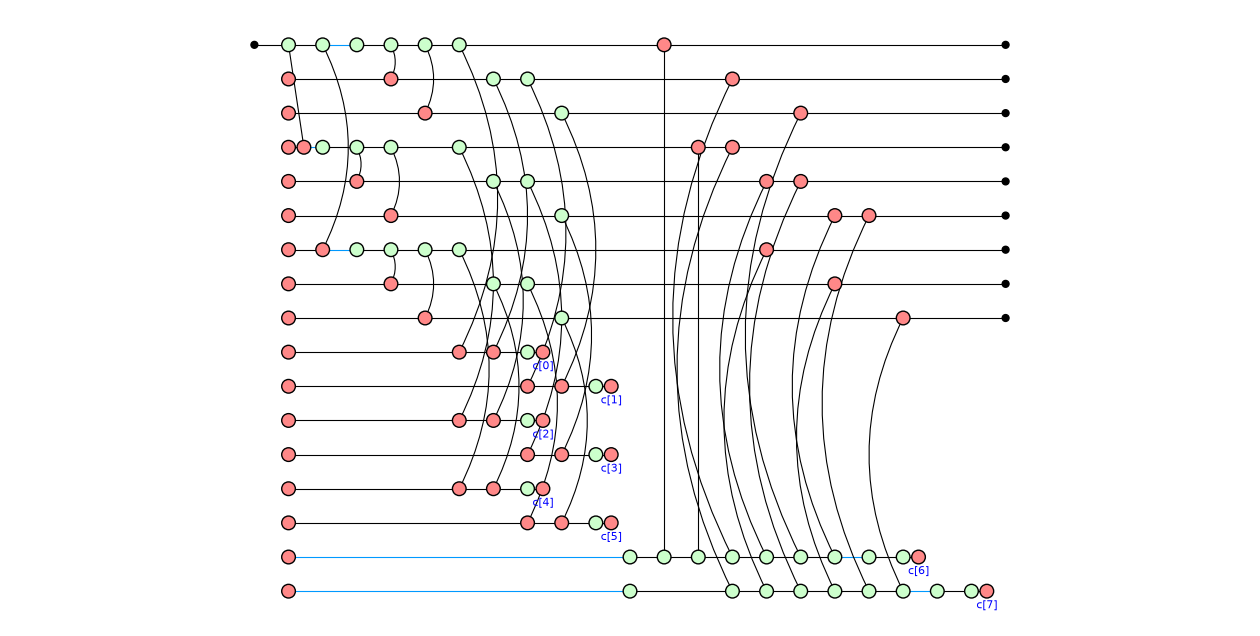

In [4]:
ENCODER = [CNOT(0, 3), CNOT(0, 6), HAD(0), HAD(3), HAD(6)] + [CNOT(b, b + k) for b in (0, 3, 6) for k in (1, 2)]
Z_CHECKS = [(0, 1), (1, 2), (3, 4), (4, 5), (6, 7), (7, 8)]
X_CHECKS = {'in order': [(0, 1, 2, 3, 4, 5), (3, 4, 5, 6, 7, 8)],
            'alternating': [(0, 3, 1, 4, 2, 5), (3, 6, 4, 7, 5, 8)]}
shor = {}
for order, x_checks in X_CHECKS.items():
    shor[order] = QProgram(17, bits=8, initial_states={q: '0' for q in range(1, 17)})
    for name, gates in (('encoder', ENCODER),
                        ('Z checks', [g for k, (a, b) in enumerate(Z_CHECKS)
                                      for g in (CNOT(a, 9 + k), CNOT(b, 9 + k), Measurement(9 + k, k))]),
                        ('X checks', [g for k, qs in enumerate(x_checks)
                                      for g in [HAD(15 + k)] + [CNOT(15 + k, q) for q in qs] + [HAD(15 + k), Measurement(15 + k, 6 + k)]])):
        c = Circuit(17, bit_amount=8)
        for gate in gates:
            c.add_gate(gate)
        shor[order].add_circuit(c, name=name)
p = shor['alternating']
draw_program(p, show_time=False, labels=False, figsize=(16, 8))

## 3. Question 1: which code

After the encoder, the [[9,1,3]] code; the second line compares it with the code PyZX builds (`pyzx.css`) from its two $X$ checks and a logical $X$. After the round of checks the code is the same, with every sign $+$: the checks find what the encoder made.

In [5]:
print(p.code_at(0))
css, _ = generate_css_encoder_graph(Mat2([[1] * 6 + [0] * 3, [0] * 3 + [1] * 6]), Mat2([[1] * 3 + [0] * 6]), 'Z-X')
css.auto_detect_io()
print("\nthe code from its X checks (pyzx.css):", p.code_at(0).same_code_as(code_of(css)))
print("\nafter the checks:")
print(p.code_at(2))

[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer +XXXXXXIII
    stabilizer +XXXIIIXXX
    stabilizer +ZZIIIIIII
    stabilizer +ZIZIIIIII
    stabilizer +IIIZZIIII
    stabilizer +IIIZIZIII
    stabilizer +IIIIIIZZI
    stabilizer +IIIIIIZIZ
    logical X XXXIIIIII   logical Z ZIIZIIZII
fixed qubits: 9 in |0>, 10 in |0>, 11 in |0>, 12 in |0>, 13 in |0>, 14 in |0>, 15 in |0>, 16 in |0>

the code from its X checks (pyzx.css): True

after the checks:
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer +XXXXXXIII
    stabilizer +XXXIIIXXX
    stabilizer +ZZIIIIIII
    stabilizer +ZIZIIIIII
    stabilizer +IIIZZIIII
    stabilizer +IIIZIZIII
    stabilizer +IIIIIIZZI
    stabilizer +IIIIIIZIZ
    logical X XXXIIIIII   logical Z ZIIZIIZII


The tool picks the logical operators of a code from its checks alone, and for a code like this one (a CSS code: each check all $X$ or all $Z$) it takes the logical $X$ to be all $X$ and the logical $Z$ all $Z$: here $X$ on qubits 0, 1, 2 and $Z$ on qubits 0, 3, 6. Shor's encoding names them the other way round: $(|000\rangle + |111\rangle)^{\otimes 3}$, his $|0\rangle$, is the state that $X$ on qubits 0, 1, 2 leaves unchanged, so for him that operator is the logical $Z$. In the tool's names Shor's $|0\rangle$ is $|{+}\rangle$, and his encoder is an $H$ followed by the tool's encoder.

## 4. Questions 2 and 3: what each part does

The level-up table, with the checks of each block's role. The encoder's check *leaves the logical state unchanged* fails for the reason above: in the tool's names the encoder is $H$. The round of checks leaves the logical qubit unchanged, in every run, and its eight results are 0 in every run (Part 5).

In [6]:
level = p.group_stages([(0, 0, 'encoder', 'encoder'), (1, 2, 'checks', 'syndrome extraction')])
print(p.summary(level))

block      role                 code before  code after  logical action  every run?  checks
0 encoder  encoder              [[1,1,1]]    [[9,1,3]]   H               yes         1 problem(s)
1 checks   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok

Block 0 'encoder' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 0
  code after:  [[9,1,3]] on qubits 0,1,2,3,4,5,6,7,8
  logical action: deterministic: every run implements H
  ok      encodes 1 logical qubit(s) into [[9,1,3]]
  PROBLEM leaves the logical state unchanged

Block 1 'checks' (syndrome extraction) -- stages 1, 2
  code before: [[9,1,3]] on qubits 0,1,2,3,4,5,6,7,8
  code after:  [[9,1,3]] on qubits 0,1,2,3,4,5,6,7,8
  logical action: deterministic: every run implements I
  measurements: 8 (8 fixed)
  ok      stays in the same code
  ok      leaves the logical state unchanged (up to a Pauli frame)
  ok      every outcome is either checked again or used


## 5. Where the whole circuit goes

The tool's reduction of the whole 17-qubit circuit (`reduce_gpf`, drawn with its boundary Hadamards, `to_graph`) is a 9-qubit encoder in normal form: an X-spider on each qubit; a Z-spider for the input, joined to qubits 6, 7, 8 (a logical $X$: $X$ on a block); two more Z-spiders, joined to qubits 0, 1, 2, 6, 7, 8 and to qubits 3 to 8 (the product of the two $X$ checks, and the second); and a Hadamard (blue) on the input. Without the Hadamard it is the code's encoder in the tool's names; with it, Shor's. The helpers and their results are gone: each result is 0 in every run, a detector.

detectors: ['c[0]', 'c[1]', 'c[2]', 'c[4]', 'c[3]', 'c[5]', 'c[6]', 'c[7]']


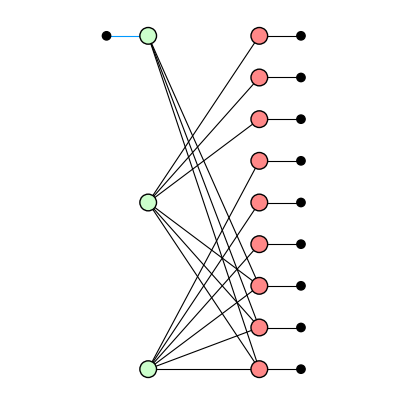

In [7]:
whole = reduce_gpf(p.quantum_graph())
print("detectors:", [str(d) for d in whole.detectors])
zx.draw_matplotlib(whole.to_graph(), figsize=(5, 5))

## 6. Errors and fault tolerance

Errors right after the encoder, as for the bit-flip code in Part 1, every pattern on up to three of the nine qubits (130 patterns for each letter):

In [8]:
print(pauli_errors(p, 0, range(9), 'X', max_weight=3))
print()
print(pauli_errors(p, 0, range(9), 'Z', max_weight=3))

X errors after stage 0 on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8:
  weight  patterns  caught  harmless  wrong
       0         1       0         1      0
       1         9       9         0      0
       2        36      36         0      0
       3        84      81         0      3
lowest weight that passes the checks and changes the output: 3 (3 pattern(s)); output error 3 p^3 to leading order
(weights up to 3 of 9 tried)



Z errors after stage 0 on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8:
  weight  patterns  caught  harmless  wrong
       0         1       0         1      0
       1         9       9         0      0
       2        36      27         9      0
       3        84      57         0     27
lowest weight that passes the checks and changes the output: 3 (27 pattern(s)); output error 27 p^3 to leading order
(weights up to 3 of 9 tried)


Every error on one or two qubits is caught or harmless ($Z$ on two qubits of one block is a check); a single $Z$, which got through the bit-flip code, is now caught by the $X$ checks. The first errors that get through are on three qubits: $X$ on a whole block (3 patterns), and $Z$ on one qubit of each block (27 patterns). The code has distance 3. That every *single* error can also be undone needs a decoder, which the tool does not have; it only counts what the checks notice.

Errors can also happen inside the round of checks. The *circuit distance* (`circuit_distance`) is the fewest faults (a Pauli after a gate, or a flipped result) that change the logical qubit without any check noticing; after the stages the tool measures the code's checks once more, without faults, so a check of that last measurement counts too. `explain` gives one lightest set. Faults of every kind (`'full'`), of type $Z$ only, and of type $X$ only, in the stages of the checks:

In [9]:
for order, q in shor.items():
    for kind, d in circuit_distance(q, 1, 2, kind=('full', 'Z', 'X')).items():
        print("{:11}  {:4} faults: {}".format(order, kind, d))
        print("             one such set:", "; ".join(str(f) for f in d.explain()))

in order     full faults: full circuit distance of stages 1-2: 1 (X -> X: 3, Z -> Z: 1)
             one such set: stage 2: X16 X6 after CX 16 6
in order     Z    faults: Z circuit distance of stages 1-2: 3 (X -> X: 3, Z -> Z: None)
             one such set: stage 1: Z5 after CX 5 12; stage 1: Z2 after CX 2 10; stage 1: Z8 after CX 8 14
in order     X    faults: X circuit distance of stages 1-2: 1 (X -> X: None, Z -> Z: 1)
             one such set: stage 2: X16 after CX 16 5


alternating  full faults: full circuit distance of stages 1-2: 3 (X -> X: 3, Z -> Z: 3)
             one such set: stage 2: Y15 Y4 after CX 15 4; stage 2: Z15 Y2 after CX 15 2; stage 2: Y16 Y6 after CX 16 6
alternating  Z    faults: Z circuit distance of stages 1-2: 3 (X -> X: 3, Z -> Z: None)
             one such set: stage 1: Z5 after CX 5 12; stage 1: Z2 after CX 2 10; stage 1: Z8 after CX 8 14
alternating  X    faults: X circuit distance of stages 1-2: 3 (X -> X: None, Z -> Z: 3)
             one such set: stage 2: X1 after CX 15 1; stage 2: X0 after CX 15 0; stage 2: X2 after CX 15 2


With the CNOTs of an $X$ check in order, one $X$ fault on the helper of the second check (qubit 16) right after its CNOT to qubit 5 is copied by the next three CNOTs onto qubits 6, 7, 8: $X$ on a whole block, the logical $X$ up to a check, and no check notices it (with faults of every kind, the same as a two-qubit fault right after the CNOT to qubit 6). With the CNOTs alternating, what one fault on a helper spreads to always flips one or two qubits of some block, which a $Z Z$ check notices; it takes three faults to get through, the distance of the code, and for $X$ faults the lightest set is the code's own, $X$ on a whole block.

## Summary

* The bit-flip code catches every single $X$, but a single $Z$ is a logical error; the tool finds this by trying every pattern.
* Shor's code is the [[9,1,3]] code; one round of its eight checks leaves the logical qubit unchanged in every run, its results always 0. The whole circuit reduces to the code's encoder; in the tool's names of the logical operators that encoder is an $H$, because Shor's $|0\rangle$ is the tool's $|{+}\rangle$.
* Every error on one or two qubits is noticed; the first unnoticed ones are on three qubits.
* The round of checks has circuit distance 3 when each $X$ check alternates between its two blocks, and 1 when it goes through its qubits in order.

What is not covered: no decoder (the tool says which errors the checks notice, not how to undo them); one round of checks, which the circuit distance follows with a last measurement of the checks without faults; and the encoder of an unknown state is never fault tolerant, so the errors are put after it.